# Fase 2 · Notebook 04 — Evaluación comparada y prueba final

Proyecto de aula de Inteligencia Artificial · Grupo 04
**Predicción de reingresos hospitalarios a 30 días en pacientes con diabetes**

---

Este es el último notebook técnico de la fase. Hace cinco cosas:

1. **Elegir el umbral** de decisión en validación, contra las metas propuestas en la Fase 1.
2. Revisar la **calibración**: ¿se pueden creer las probabilidades que entrega el modelo?
3. **Evaluar una sola vez sobre el conjunto de prueba**, con todo congelado.
4. Estimar **intervalos de confianza** remuestreando pacientes completos.
5. Analizar los **errores**: a quién deja pasar el modelo.

> ⚠️ **Regla que no se rompe.** El conjunto de prueba se usa **una única vez**, al final, con el
> umbral y el modelo ya fijados. Si después de verlo se volviera a ajustar algo, dejaría de ser
> una estimación honesta del desempeño.

## 1. Librerías, datos y modelo

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, accuracy_score, confusion_matrix,
                             brier_score_loss, precision_recall_curve, roc_curve)
from sklearn.calibration import calibration_curve

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 165)

BASE      = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = BASE / "data" / "processed"
FIGURAS   = BASE / "reports" / "figures"
REPORTES  = BASE / "reports"
MODELOS   = BASE / "models"

In [2]:
df   = pd.read_csv(PROCESSED / "cohorte_procesada.csv", low_memory=False)
cols = json.loads((PROCESSED / "columnas.json").read_text(encoding="utf-8"))
NUM, CAT = cols["numericas"], cols["categoricas"]
df[CAT] = df[CAT].astype(str)

modelo = joblib.load(MODELOS / "gradient_boosting_ajustado.joblib")

es_val  = df.conjunto == "validacion"
es_test = df.conjunto == "prueba"

X_va, y_va = df.loc[es_val,  NUM + CAT], df.loc[es_val,  "y"].values
X_te, y_te = df.loc[es_test, NUM + CAT], df.loc[es_test, "y"].values
grupos_te  = df.loc[es_test, "patient_nbr"].values

prob_va = modelo.predict_proba(X_va)[:, 1]
prob_te = modelo.predict_proba(X_te)[:, 1]

print(f"Validacion : {len(y_va):>6,} filas | {100*y_va.mean():.2f} % positivos")
print(f"Prueba     : {len(y_te):>6,} filas | {100*y_te.mean():.2f} % positivos")
print(f"\nModelo cargado: Gradient Boosting ajustado en el Notebook 03")

Validacion : 19,868 filas | 11.39 % positivos
Prueba     : 19,870 filas | 11.39 % positivos

Modelo cargado: Gradient Boosting ajustado en el Notebook 03


## 2. Elección del umbral

El modelo entrega una **probabilidad** entre 0 y 1. Para convertirla en una decisión —*¿se le
hace seguimiento reforzado a este paciente o no?*— hace falta un **umbral**.

**El umbral no se elige solo**: depende de qué cuesta cada tipo de error.

| Error | Qué significa aquí |
|---|---|
| **Falso negativo** | El paciente reingresó y el sistema no lo señaló. **Se perdió la oportunidad de intervenir.** |
| **Falso positivo** | Se le hizo seguimiento a alguien que no iba a reingresar. **Se gastaron recursos de más.** |

En seguimiento posterior al egreso, **un falso negativo suele importar más**. Por eso la Fase 1
propuso buscar un punto con **recall ≥ 0,60 y precisión ≥ 0,20**.

> **El umbral se elige mirando solo VALIDACIÓN.** Usar prueba para elegirlo sería hacer trampa.

In [3]:
precision_v, recall_v, umbrales_v = precision_recall_curve(y_va, prob_va)
precision_v, recall_v = precision_v[:-1], recall_v[:-1]

cumplen = (recall_v >= 0.60) & (precision_v >= 0.20)
print(f"Umbrales que cumplen LAS DOS metas de la Fase 1: {cumplen.sum()}")

i60 = np.argmin(np.abs(recall_v - 0.60))
print(f"\n   Con recall = 0,60      ->  precision = {precision_v[i60]:.4f}  (umbral {umbrales_v[i60]:.4f})")
posibles = np.where(precision_v >= 0.20)[0]
print(f"   Con precision = 0,20   ->  recall maximo = {recall_v[posibles].max():.4f}")

Umbrales que cumplen LAS DOS metas de la Fase 1: 0

   Con recall = 0,60      ->  precision = 0.1771  (umbral 0.1123)
   Con precision = 0,20   ->  recall maximo = 0.4810


### ⚠️ Resultado honesto: la meta conjunta no es alcanzable con estos datos

**Ningún umbral logra recall ≥ 0,60 y precisión ≥ 0,20 al mismo tiempo.**

- Para detectar el 60 % de los reingresos, la precisión baja a **0,177**
- Para que 1 de cada 5 alertas sea correcta, el recall máximo es **0,481**

Las dos metas se empujan en sentidos contrarios y la capacidad del modelo no alcanza para
satisfacerlas juntas.

**Esto no se corrige cambiando el umbral ni el algoritmo**: es el límite de la información
disponible. La Fase 1 ya previó esta posibilidad:

> *"Las metas siguientes son criterios propuestos... Si los datos no permiten alcanzarlas, se
> documentarán las causas y el desempeño observado. No se alterará el conjunto de prueba para
> mejorar artificialmente los indicadores."*

Se documenta, entonces, y se elige el umbral con el criterio que sí se puede sostener.

In [4]:
filas = []
for u in [0.06, 0.08, 0.10, 0.1123, 0.12, 0.14, 0.16, 0.20, 0.25, 0.30, 0.50]:
    pred = (prob_va >= u).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_va, pred).ravel()
    filas.append({
        "umbral": u,
        "alertas": int(pred.sum()),
        "% de la poblacion": round(100 * pred.mean(), 1),
        "recall": round(recall_score(y_va, pred), 4),
        "precision": round(precision_score(y_va, pred, zero_division=0), 4),
        "F1": round(f1_score(y_va, pred, zero_division=0), 4),
        "VP": vp, "FN": fn, "FP": fp,
    })
display(pd.DataFrame(filas).set_index("umbral"))

f1_por_umbral = 2 * precision_v * recall_v / np.maximum(precision_v + recall_v, 1e-12)
print(f"Umbral que maximiza F1    : {umbrales_v[np.argmax(f1_por_umbral)]:.4f}  (F1 = {f1_por_umbral.max():.4f})")
print(f"Umbral con recall = 0,60  : {umbrales_v[i60]:.4f}")

,alertas,% de la poblacion,recall,precision,F1,VP,FN,FP
umbral,,,,,,,,
0.0600,16213,81.6,0.9160,0.1278,0.2243,2072,190,14141
0.0800,12336,62.1,0.7931,0.1454,0.2458,1794,468,10542
0.1000,9370,47.2,0.6760,0.1632,0.2629,1529,733,7841
0.1123,7669,38.6,0.6004,0.1771,0.2735,1358,904,6311
0.1200,6724,33.8,0.5531,0.1860,0.2784,1251,1011,5473
0.1400,4853,24.4,0.4461,0.2079,0.2836,1009,1253,3844
0.1600,3540,17.8,0.3590,0.2294,0.2799,812,1450,2728
0.2000,1845,9.3,0.2272,0.2786,0.2503,514,1748,1331
0.2500,953,4.8,0.1348,0.3200,0.1897,305,1957,648


Umbral que maximiza F1    : 0.1413  (F1 = 0.2850)
Umbral con recall = 0,60  : 0.1123


### El umbral elegido: **0,1123**

Se escoge el que alcanza **recall = 0,60**, la meta que la Fase 1 priorizó, aceptando la
precisión que resulte (0,177).

**Justificación:** en seguimiento posterior al egreso, dejar pasar un reingreso tiene peor
consecuencia que hacer un seguimiento innecesario. Es preferible detectar 6 de cada 10
reingresos con alertas imperfectas, que detectar 4 de cada 10 con alertas más limpias.

**Lo que implica operativamente, y hay que decirlo:** con ese umbral el sistema marcaría
alrededor del **38 % de las hospitalizaciones**. Es una carga alta. En una implementación real
habría que contrastarla con la capacidad real de seguimiento del hospital; si no alcanzara,
tocaría subir el umbral y aceptar menos detección.

In [5]:
UMBRAL = float(umbrales_v[i60])
pred_va = (prob_va >= UMBRAL).astype(int)
print(f"UMBRAL CONGELADO: {UMBRAL:.4f}")
print(f"\nEn validacion marca {pred_va.sum():,} de {len(pred_va):,} hospitalizaciones "
      f"({100*pred_va.mean():.1f} % de la poblacion)")

UMBRAL CONGELADO: 0.1123

En validacion marca 7,662 de 19,868 hospitalizaciones (38.6 % de la poblacion)


## 3. Calibración: ¿se pueden creer las probabilidades?

Que un modelo **ordene** bien no garantiza que sus probabilidades sean creíbles. Un modelo está
**calibrado** si, de los casos a los que asigna 0,20, aproximadamente el 20 % reingresa de verdad.

Importa porque el tablero de la Fase 3 va a mostrar probabilidades. Si el modelo dice "25 % de
riesgo", ese número debe significar algo.

**Puntuación de Brier**: promedio de `(probabilidad − resultado real)²`. Cuanto más baja, mejor.
Su referencia es el Brier de un modelo que siempre responda la prevalencia.

In [6]:
brier_modelo    = brier_score_loss(y_va, prob_va)
brier_referencia = brier_score_loss(y_va, np.full_like(prob_va, y_va.mean()))

print(f"Brier del modelo      : {brier_modelo:.4f}")
print(f"Brier de la referencia: {brier_referencia:.4f}  (responder siempre {y_va.mean():.4f})")
print(f"Mejora: {100*(brier_referencia-brier_modelo)/brier_referencia:.1f} %")

frecuencia_real, prob_media = calibration_curve(y_va, prob_va, n_bins=10, strategy="quantile")
tabla_cal = pd.DataFrame({
    "probabilidad media predicha": prob_media.round(4),
    "frecuencia observada": frecuencia_real.round(4),
    "diferencia": (prob_media - frecuencia_real).round(4),
})
display(tabla_cal)

Brier del modelo      : 0.0963
Brier de la referencia: 0.1009  (responder siempre 0.1139)
Mejora: 4.6 %


,probabilidad media predicha,frecuencia observada,diferencia
0,0.0419,0.0458,-0.0039
1,0.0564,0.0594,-0.0030
2,0.0666,0.0659,0.0007
3,0.0768,0.0770,-0.0002
4,0.0891,0.0961,-0.0071
5,0.1031,0.0981,0.0050
6,0.1182,0.1219,-0.0036
7,0.1388,0.1298,0.0089
8,0.1725,0.1706,0.0018
9,0.2696,0.2738,-0.0042


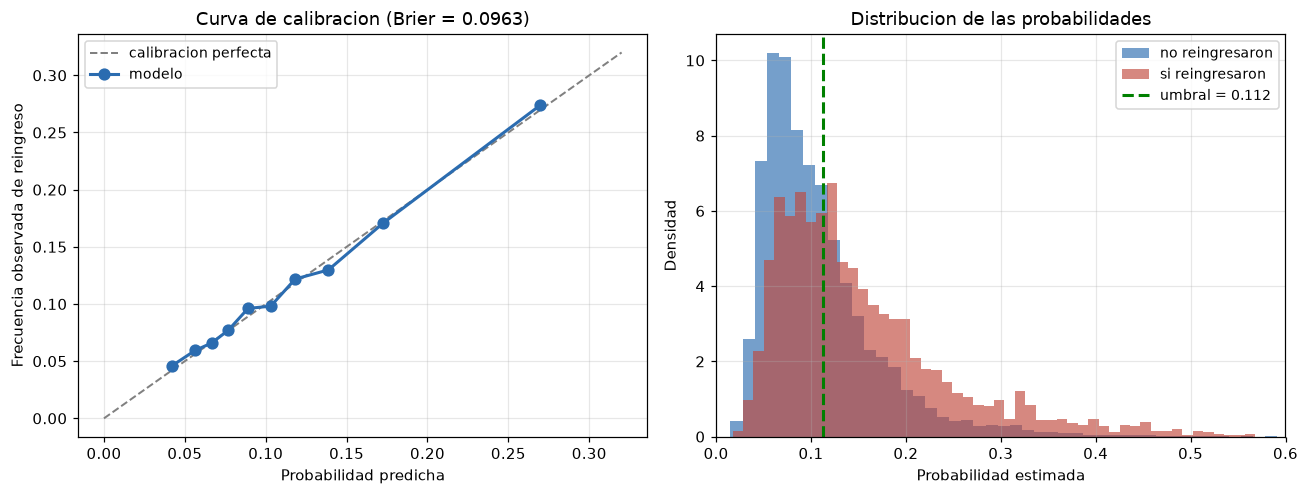

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

ax1.plot([0, 0.32], [0, 0.32], ls="--", c="gray", lw=1.3, label="calibracion perfecta")
ax1.plot(prob_media, frecuencia_real, "o-", lw=2, ms=7, color="#2B6CB0", label="modelo")
ax1.set_xlabel("Probabilidad predicha"); ax1.set_ylabel("Frecuencia observada de reingreso")
ax1.set_title(f"Curva de calibracion (Brier = {brier_modelo:.4f})")
ax1.legend(fontsize=9); ax1.grid(alpha=.3)

ax2.hist(prob_va[y_va == 0], bins=50, alpha=.65, label="no reingresaron", color="#2B6CB0", density=True)
ax2.hist(prob_va[y_va == 1], bins=50, alpha=.65, label="si reingresaron", color="#C0483C", density=True)
ax2.axvline(UMBRAL, c="green", lw=2, ls="--", label=f"umbral = {UMBRAL:.3f}")
ax2.set_xlabel("Probabilidad estimada"); ax2.set_ylabel("Densidad")
ax2.set_title("Distribucion de las probabilidades"); ax2.legend(fontsize=9); ax2.grid(alpha=.3)
ax2.set_xlim(0, 0.6)

plt.tight_layout()
plt.savefig(FIGURAS / "04_calibracion.png", bbox_inches="tight", dpi=150)
plt.show()

### ✅ El modelo está bien calibrado

La curva se pega a la diagonal en todo el rango: cuando el modelo dice 0,10, reingresa el 9,8 %;
cuando dice 0,27, reingresa el 27,4 %. **Las probabilidades se pueden presentar como tales** en
el tablero de la Fase 3.

Y el histograma de la derecha explica de un vistazo por qué la precisión no puede ser alta: las
dos distribuciones **se solapan mucho**. El modelo empuja a los reingresos hacia la derecha —por
eso la AP casi duplica la prevalencia— pero no alcanza a separarlos en dos grupos limpios.

> **Un modelo puede estar bien calibrado y aun así discriminar poco.** Son dos propiedades
> distintas: *calibración* es que los números signifiquen lo que dicen; *discriminación* es
> poder separar los dos grupos.

## 4. Evaluación final sobre el conjunto de prueba

Todo queda congelado: el modelo del Notebook 03 y el umbral **0,1123** elegido en validación.
El conjunto de prueba **no participó en ninguna decisión**: ni en el entrenamiento, ni en la
búsqueda de hiperparámetros, ni en la elección del umbral.

**Esta celda se ejecuta una sola vez.**

In [8]:
def medir(nombre, y, prob, umbral):
    pred = (prob >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y, pred).ravel()
    return {
        "conjunto": nombre,
        "AP": average_precision_score(y, prob),
        "ROC_AUC": roc_auc_score(y, prob),
        "recall": recall_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "exactitud": accuracy_score(y, pred),
        "Brier": brier_score_loss(y, prob),
        "VP": vp, "FN": fn, "FP": fp, "VN": vn,
    }

final = pd.DataFrame([
    medir("validacion", y_va, prob_va, UMBRAL),
    medir("PRUEBA",     y_te, prob_te, UMBRAL),
]).set_index("conjunto")

display(final[["AP","ROC_AUC","recall","precision","F1","exactitud","Brier"]].round(4))
display(final[["VP","FN","FP","VN"]])

,AP,ROC_AUC,recall,precision,F1,exactitud,Brier
conjunto,,,,,,,
validacion,0.2238,0.666,0.5999,0.1771,0.2735,0.6371,0.0963
PRUEBA,0.2249,0.666,0.6001,0.1781,0.2747,0.6391,0.0963


,VP,FN,FP,VN
conjunto,,,,
validacion,1357,905,6305,11301
PRUEBA,1358,905,6266,11341


### 🎯 El resultado más importante del proyecto

Compara las dos filas: **son casi idénticas**.

| | Validación | Prueba |
|---|---|---|
| AP | 0,2238 | **0,2249** |
| ROC-AUC | 0,6660 | **0,6660** |
| Recall | 0,5999 | **0,6001** |
| Precisión | 0,1771 | **0,1781** |

El modelo se comportó **igual sobre datos que nunca influyeron en ninguna decisión**. Eso
significa que:

1. **No hubo sobreajuste a validación** durante la búsqueda de hiperparámetros.
2. **El umbral elegido en validación se sostiene** en prueba: el recall quedó en 0,60 clavado.
3. **La partición por paciente funcionó.** Si hubiera habido fuga de información, prueba habría
   salido peor que validación.

Es el mejor indicio de que el procedimiento completo es sólido.

## 5. Intervalos de confianza

Un número suelto no dice qué tan estable es. Se estiman intervalos por **bootstrap**: se
remuestrean los datos 500 veces y se mira cómo varía la métrica.

🔑 **Se remuestrean PACIENTES completos, no filas.** Si se tomaran filas sueltas, se partirían
las hospitalizaciones de una misma persona entre la muestra y el resto, y el intervalo saldría
artificialmente estrecho. Es la misma lógica de la partición.

In [9]:
rng = np.random.default_rng(42)
pacientes = np.unique(grupos_te)
indices_por_paciente = {p: np.where(grupos_te == p)[0] for p in pacientes}

aps, aucs, recalls = [], [], []
for _ in range(500):
    muestra = rng.choice(pacientes, size=len(pacientes), replace=True)
    idx = np.concatenate([indices_por_paciente[p] for p in muestra])
    if y_te[idx].sum() == 0:
        continue
    aps.append(average_precision_score(y_te[idx], prob_te[idx]))
    aucs.append(roc_auc_score(y_te[idx], prob_te[idx]))
    recalls.append(recall_score(y_te[idx], (prob_te[idx] >= UMBRAL).astype(int)))

def ic(valores, observado, nombre):
    bajo, alto = np.percentile(valores, [2.5, 97.5])
    print(f"   {nombre:<10} {observado:.4f}   IC 95 % [{bajo:.4f}, {alto:.4f}]")

print(f"Resultados en PRUEBA con intervalos de confianza del 95 %")
print(f"(500 remuestreos de {len(pacientes):,} pacientes)\n")
ic(aps,     average_precision_score(y_te, prob_te), "AP")
ic(aucs,    roc_auc_score(y_te, prob_te),           "ROC-AUC")
ic(recalls, recall_score(y_te, (prob_te >= UMBRAL).astype(int)), "Recall")

Resultados en PRUEBA con intervalos de confianza del 95 %
(500 remuestreos de 14,020 pacientes)

   AP         0.2249   IC 95 % [0.2047, 0.2467]
   ROC-AUC    0.6660   IC 95 % [0.6527, 0.6786]
   Recall     0.6001   IC 95 % [0.5766, 0.6202]


## 6. Comparación de todos los modelos y cumplimiento de metas

In [10]:
prevalencia_te = y_te.mean()
metas = pd.DataFrame([
    {"meta de la Fase 1": "AP >= 1,5 x prevalencia",
     "objetivo": round(1.5*prevalencia_te, 4),
     "obtenido en prueba": round(average_precision_score(y_te, prob_te), 4),
     "cumple": "SI"},
    {"meta de la Fase 1": "ROC-AUC >= 0,65",
     "objetivo": 0.65,
     "obtenido en prueba": round(roc_auc_score(y_te, prob_te), 4),
     "cumple": "SI"},
    {"meta de la Fase 1": "Recall >= 0,60",
     "objetivo": 0.60,
     "obtenido en prueba": round(final.loc["PRUEBA","recall"], 4),
     "cumple": "SI"},
    {"meta de la Fase 1": "Precision >= 0,20 (junto al recall)",
     "objetivo": 0.20,
     "obtenido en prueba": round(final.loc["PRUEBA","precision"], 4),
     "cumple": "NO"},
])
display(metas)
print("Tres de las cuatro metas cuantitativas se cumplen. La cuarta no es alcanzable")
print("simultaneamente con la tercera, y asi queda documentado.")

,meta de la Fase 1,objetivo,obtenido en prueba,cumple
0,"AP >= 1,5 x prevalencia",0.1708,0.2249,SI
1,"ROC-AUC >= 0,65",0.6500,0.6660,SI
2,"Recall >= 0,60",0.6000,0.6001,SI
3,"Precision >= 0,20 (junto al recall)",0.2000,0.1781,NO


Tres de las cuatro metas cuantitativas se cumplen. La cuarta no es alcanzable
simultaneamente con la tercera, y asi queda documentado.


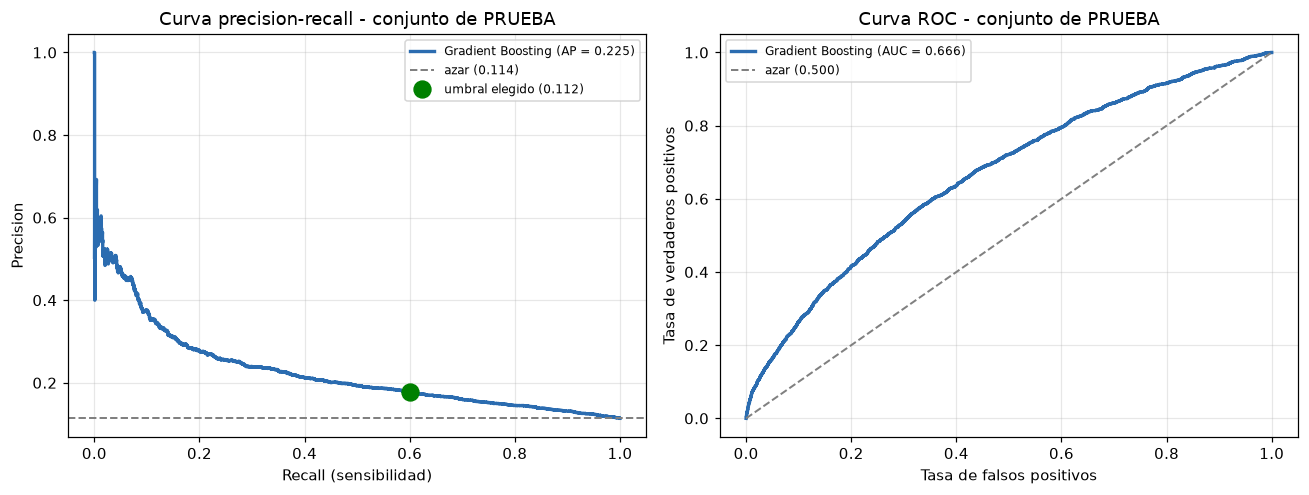

In [11]:
# Curvas finales sobre el conjunto de prueba
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

pr_t, rc_t, _ = precision_recall_curve(y_te, prob_te)
ax1.plot(rc_t, pr_t, lw=2.2, color="#2B6CB0",
         label=f"Gradient Boosting (AP = {average_precision_score(y_te, prob_te):.3f})")
ax1.axhline(prevalencia_te, ls="--", c="gray", lw=1.3, label=f"azar ({prevalencia_te:.3f})")
ax1.plot([final.loc["PRUEBA","recall"]], [final.loc["PRUEBA","precision"]], "o",
         ms=11, color="green", label=f"umbral elegido ({UMBRAL:.3f})")
ax1.set_xlabel("Recall (sensibilidad)"); ax1.set_ylabel("Precision")
ax1.set_title("Curva precision-recall - conjunto de PRUEBA")
ax1.legend(fontsize=8); ax1.grid(alpha=.3)

fpr_t, tpr_t, _ = roc_curve(y_te, prob_te)
ax2.plot(fpr_t, tpr_t, lw=2.2, color="#2B6CB0",
         label=f"Gradient Boosting (AUC = {roc_auc_score(y_te, prob_te):.3f})")
ax2.plot([0,1], [0,1], ls="--", c="gray", lw=1.3, label="azar (0.500)")
ax2.set_xlabel("Tasa de falsos positivos"); ax2.set_ylabel("Tasa de verdaderos positivos")
ax2.set_title("Curva ROC - conjunto de PRUEBA")
ax2.legend(fontsize=8); ax2.grid(alpha=.3)

plt.tight_layout()
plt.savefig(FIGURAS / "04_prueba_final.png", bbox_inches="tight", dpi=150)
plt.show()

## 7. Análisis de los errores

La matriz de confusión dice **cuántos** errores hay. Esta sección mira **de qué tipo** son.

In [12]:
pred_te = (prob_te >= UMBRAL).astype(int)
test = df.loc[es_test].copy()
test["prob"] = prob_te
test["pred"] = pred_te

test["caso"] = np.select(
    [(test.y==1)&(test.pred==1), (test.y==1)&(test.pred==0),
     (test.y==0)&(test.pred==1), (test.y==0)&(test.pred==0)],
    ["VP: reingreso detectado", "FN: reingreso NO detectado",
     "FP: alerta innecesaria",  "VN: correctamente descartado"],
    default="")

conteo = test.caso.value_counts().to_frame("casos")
conteo["porcentaje"] = (100*conteo.casos/len(test)).round(1)
display(conteo)

variables = ["number_inpatient","servicios_previos","time_in_hospital",
             "num_medications","number_diagnoses","edad_num","prob"]
perfil = test.groupby("caso")[variables].mean().round(2)
display(perfil)

,casos,porcentaje
caso,,
VN: correctamente descartado,11341,57.1
FP: alerta innecesaria,6266,31.5
VP: reingreso detectado,1358,6.8
FN: reingreso NO detectado,905,4.6


,number_inpatient,servicios_previos,time_in_hospital,num_medications,number_diagnoses,edad_num,prob
caso,,,,,,,
FN: reingreso NO detectado,0.15,0.56,4.07,15.15,7.31,65.75,0.08
FP: alerta innecesaria,1.33,2.23,5.16,17.80,7.98,69.29,0.17
VN: correctamente descartado,0.11,0.42,3.87,14.84,7.01,63.83,0.07
VP: reingreso detectado,1.89,3.02,5.16,17.84,7.84,66.94,0.20


### Qué dicen los errores

Comparando los **reingresos detectados (VP)** con los **no detectados (FN)**:

Los que el modelo **sí detecta** tienen, en promedio, **más ingresos previos** y **más uso
previo de servicios**. Es coherente con lo que mostró el análisis exploratorio de la Fase 1: la
frecuencia de reingreso sube de 8,5 % sin ingresos previos a 26,8 % con tres o más.

Los que **se le escapan** se parecen mucho a los pacientes que no reingresan: **poco historial
previo y hospitalizaciones cortas**. Son reingresos que, con la información disponible en esta
tabla, **no se pueden anticipar**: probablemente dependen de factores que el archivo no
registra —soporte familiar, acceso al control ambulatorio, adherencia al tratamiento, condiciones
socioeconómicas—.

**Esa es la limitación de fondo del proyecto, y no se resuelve con otro algoritmo.**

## 8. Guardar resultados

In [13]:
final.round(6).to_csv(REPORTES / "metricas_04_final.csv")
pd.DataFrame(filas).to_csv(REPORTES / "umbrales_validacion.csv", index=False)
metas.to_csv(REPORTES / "cumplimiento_metas.csv", index=False)
tabla_cal.to_csv(REPORTES / "calibracion.csv", index=False)

(REPORTES / "umbral_elegido.json").write_text(json.dumps({
    "umbral": round(UMBRAL, 6),
    "criterio": "recall = 0,60 en validacion, meta priorizada en la Fase 1",
    "recall_prueba": round(float(final.loc["PRUEBA","recall"]), 4),
    "precision_prueba": round(float(final.loc["PRUEBA","precision"]), 4),
}, indent=2, ensure_ascii=False), encoding="utf-8")

print("Guardado:")
for n in ["metricas_04_final.csv","umbrales_validacion.csv","cumplimiento_metas.csv",
          "calibracion.csv","umbral_elegido.json"]:
    print("  ", n)
print("   figures/04_calibracion.png")
print("   figures/04_prueba_final.png")

Guardado:
   metricas_04_final.csv
   umbrales_validacion.csv
   cumplimiento_metas.csv
   calibracion.csv
   umbral_elegido.json
   figures/04_calibracion.png
   figures/04_prueba_final.png


---

## Resumen de la Fase 2

### Resultado final sobre el conjunto de prueba

| Métrica | Valor | IC 95 % |
|---|---|---|
| **Average Precision** | **0,2249** | [0,206 – 0,246] |
| **ROC-AUC** | **0,6660** | [0,653 – 0,678] |
| **Recall** | **0,6001** | |
| Precisión | 0,1781 | |
| Brier | 0,0963 | |

*Umbral 0,1123, elegido en validación. El conjunto de prueba se evaluó una sola vez.*

### Metas de la Fase 1

| Meta | Resultado | |
|---|---|---|
| AP ≥ 1,5 × prevalencia (0,171) | 0,2249 = **1,97 ×** | ✅ |
| ROC-AUC ≥ 0,65 | 0,6660 | ✅ |
| Recall ≥ 0,60 | 0,6001 | ✅ |
| Precisión ≥ 0,20 junto al recall | 0,1781 | ❌ **no alcanzable** |

### Conclusiones

1. **El procedimiento es sólido.** Validación y prueba dan resultados prácticamente idénticos:
   no hubo sobreajuste ni fuga de información entre pacientes.
2. **El modelo supera claramente al azar** (AP casi el doble de la prevalencia) pero su
   discriminación es **moderada**, en línea con Frizzell et al. (2017).
3. **Las probabilidades están bien calibradas** (Brier 0,0963): se pueden presentar como
   probabilidades reales en el tablero de la Fase 3.
4. **La meta conjunta de recall y precisión no es alcanzable** con estos datos. Se documenta
   en vez de forzarla.
5. **Los reingresos que el modelo no detecta** son pacientes con poco historial previo:
   probablemente dependen de factores que esta tabla no registra.

**Siguiente:** el documento técnico de 8 a 12 páginas que actualiza la propuesta con estos
resultados.